# Solutions · 03 · Binary distillation: the McCabe-Thiele method

Worked solutions to the exercises of [notebook 03](../notebooks/03_binary_distillation_mccabe_thiele.ipynb). Try each exercise
yourself before reading its solution - the learning happens in the attempt. Solutions are one way to
answer each question; other correct approaches exist.

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize
from engsep import distillation as dist
from engsep import vle
from engsep.vle import y_from_alpha
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

In [2]:
alpha = vle.geometric_mean_alpha(("benzene", "toluene"), ideal=True)
y_eq = lambda x: y_from_alpha(x, alpha)
xD, xB, zF = 0.95, 0.05, 0.45

## Exercise 1

Design the benzene-toluene column for a 40 % vapour feed (q = 0.6) and for a feed preheated to its bubble point; compare stages, feed location and R_min. Estimate which is cheaper if a preheater costs 20 % of a reboiler.

In [3]:
for q, label in ((0.6, "40 % vaporised"), (1.0, "bubble-point liquid")):
    rm = dist.minimum_reflux(y_eq, xD, zF, q)["R_min"]
    R = 1.3 * rm
    mt = dist.mccabe_thiele(y_eq, xD, xB, zF, R, q)
    print(f"{label:<20}: R_min = {rm:.3f}, at 1.3 R_min = {R:.2f}: {mt['stages']} stages, feed stage {mt['feed_stage']}; reboiler vapour (R+1) D = {(R + 1) * 44.4:.0f} kmol/h")
print("preheating to the bubble point: R_min falls by a third and the reboiler vapour by a quarter; a preheater at 20 % of a reboiler's cost that saves 25 % of the reboiler duty pays back")

40 % vaporised      : R_min = 1.656, at 1.3 R_min = 2.15: 13 stages, feed stage 7; reboiler vapour (R+1) D = 140 kmol/h
bubble-point liquid : R_min = 1.282, at 1.3 R_min = 1.67: 14 stages, feed stage 7; reboiler vapour (R+1) D = 118 kmol/h
preheating to the bubble point: R_min falls by a third and the reboiler vapour by a quarter; a preheater at 20 % of a reboiler's cost that saves 25 % of the reboiler duty pays back


The vapour feed forces the rectifying section to handle the extra vapour, so it needs more reflux and more
stages; preheating the feed to its bubble point (with waste heat, often the bottoms) cuts the minimum reflux
by a third. Feed preheating is one of the cheapest energy savings in distillation.

## Exercise 2

For the ethanol-water column, plot the number of stages against the distillate purity from 0.70 to 0.88 at R = 3 and R = 6. Explain the shape from the equilibrium curve, and what happens at 0.89.

      R = 3  R = 6
0.70      4      4
0.72      5      4
0.74      5      5
0.76      6      5
0.78      7      6
0.80      8      7
0.82     10      8
0.84     14     11
0.86     25     16
0.88    500     37


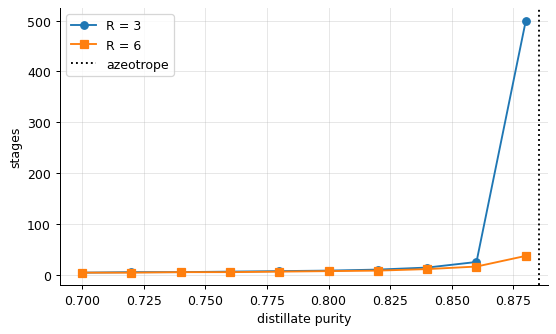

In [4]:
y_ew = lambda x: vle.equilibrium_y(("ethanol", "water"), x)
xDs = np.linspace(0.70, 0.88, 10)
rows = []
for R in (3.0, 6.0):
    rows.append([dist.mccabe_thiele(y_ew, xd, 0.02, 0.30, R)["stages"] for xd in xDs])
print(pd.DataFrame(np.array(rows).T, index=np.round(xDs, 3), columns=["R = 3", "R = 6"]).to_string())
plt.plot(xDs, rows[0], "o-", label="R = 3"); plt.plot(xDs, rows[1], "s-", label="R = 6"); plt.axvline(vle.azeotrope("ethanol", "water")["x"], color="k", ls=":", label="azeotrope"); plt.xlabel("distillate purity"); plt.ylabel("stages"); plt.legend(); plt.show()

The stage count barely moves up to 80 % ethanol and then climbs steeply as the distillate approaches the
azeotrope, where the equilibrium curve meets the diagonal and the steps shrink to nothing. Doubling the
reflux helps little: the pinch is in the equilibrium curve, not the operating line. At 0.885 no reflux ratio
and no number of stages will do.

## Exercise 3

**Implement it yourself:** write your own McCabe-Thiele stepping function for a saturated-liquid feed and reproduce the stage count and feed stage of the benzene-toluene example.

In [5]:
def mccabe_thiele_sat_liquid(y_eq, xD, xB, zF, R):
    x = y = xD
    stages, feed = 0, None
    x_int = zF
    y_int = R / (R + 1) * zF + xD / (R + 1)
    slope_s = (y_int - xB) / (x_int - xB)
    while x > xB:
        x = optimize.brentq(lambda xx: y_eq(xx) - y, 0, 1)
        stages += 1
        if feed is None and x <= zF:
            feed = stages
        if x <= xB:
            break
        y = R / (R + 1) * x + xD / (R + 1) if x > zF else xB + slope_s * (x - xB)
    return stages, feed
print("by hand:", mccabe_thiele_sat_liquid(y_eq, xD, xB, zF, 2.0), "; library:", (dist.mccabe_thiele(y_eq, xD, xB, zF, 2.0)["stages"], dist.mccabe_thiele(y_eq, xD, xB, zF, 2.0)["feed_stage"]))

by hand: (12, 6) ; library: (12, 6)


For a saturated-liquid feed the operating lines meet at $x = z_F$, and the stepping loop is a dozen lines
that reproduce the library's count and feed stage.